# code_054 · Encoding categories and unknown values

**Book:** section 11.3. A self-contained preprocessing laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_11_GUIDE.md), [run evidence](../CHAPTER_11_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_054).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. Model-family comparisons and documentary contract checks retain their declared limits; there are no field-validity or universal-preprocessing claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1154;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1154


<a id="vocabulary"></a>
## An integer category code does not supply a physical distance

A small vocabulary has bolted, welded and pinned connections. OneHotEncoder uses all training categories with handle_unknown=ignore and no dropped column. An unseen bonded type yields all zeros, which is a documented fallback, not a learned bonded effect. OrdinalEncoder uses an explicit order with unknown -1; a linear model would treat those integers as ordered/equally spaced unless additional structure changes that interpretation. No such physical order is asserted here.


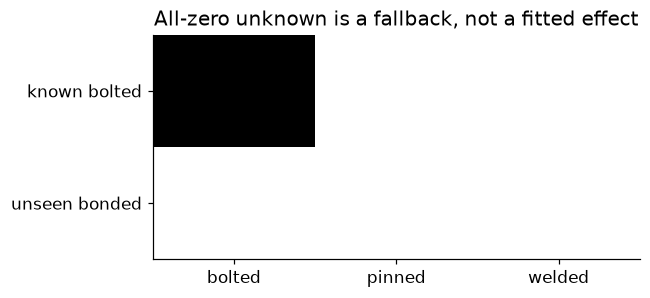

In [2]:
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,TargetEncoder
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
vocabulary=np.array(['bolted','welded','pinned'],dtype=object)[:,None]
one=OneHotEncoder(handle_unknown='ignore',sparse_output=False).fit(vocabulary);encoded=one.transform(np.array(['bolted','bonded'],dtype=object)[:,None]);assert encoded[1].sum()==0 and encoded[0].sum()==1
ordinal=OrdinalEncoder(categories=[['bolted','welded','pinned']],handle_unknown='use_encoded_value',unknown_value=-1).fit(vocabulary);assert ordinal.transform([['bonded']])[0,0]==-1
RESULTS['one_hot_columns']=one.get_feature_names_out().tolist();RESULTS['unseen_one_hot']=encoded[1].tolist();RESULTS['unseen_ordinal']=-1
fig,ax=plt.subplots(figsize=(5.8,2.6));ax.imshow(encoded,cmap='Greys',vmin=0,vmax=1,aspect='auto');ax.set(yticks=[0,1],yticklabels=['known bolted','unseen bonded'],xticks=np.arange(3),xticklabels=one.categories_[0],title='All-zero unknown is a fallback, not a fitted effect');plt.show()


<a id="crossfit"></a>
## Hold whole buildings out of target statistics

There are 75 buildings, six members each. Connection effects are bolted .2, welded 1.0, pinned -.5 mm; each building also has an independent Normal(0,.7) offset. Target = 2 + connection effect + building offset + noise .15. Train on 50 buildings, development on 10, final on 15; deployment concerns new buildings. Both connection and building ID are encoded. TargetEncoder uses continuous targets, fixed smoothing 5 and explicit five GroupKFold splits over the 50 training buildings. Every training member is encoded from other buildings' labels, then the stored full-training mapping transforms new buildings. All new building IDs fall back to the full-training target mean.

For comparison only, fit(...).transform(training) leaks the same buildings' labels into their training features. Fit the same fixed Ridge alpha=1 downstream for both representations; scores are diagnostic, with no procedure selection. This uses scikit-learn 1.9's iterable-cv interface. The perturbation check alters every target in one held-out fold and proves that fold's cross-fitted encodings do not change.


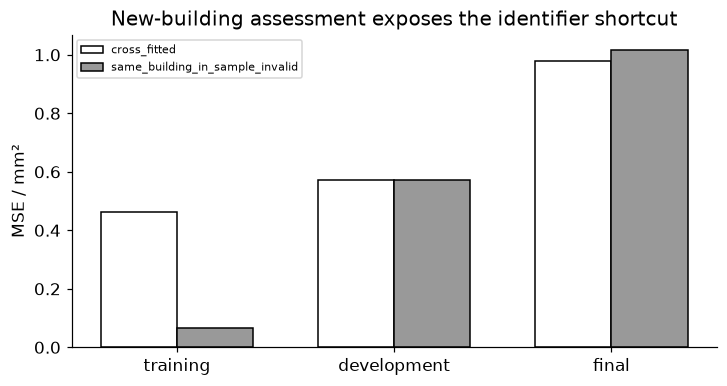

In [3]:
groups=np.repeat(np.arange(75),6);connection=rng.choice(vocabulary[:,0],len(groups));effect={'bolted':.2,'welded':1.,'pinned':-.5}
y=2+np.array([effect[c] for c in connection])+rng.normal(0,.7,75)[groups]+rng.normal(0,.15,len(groups))
X=np.column_stack([connection,np.array([f'building-{g}' for g in groups])]);tr=np.flatnonzero(groups<50);dv=np.flatnonzero((groups>=50)&(groups<60));te=np.flatnonzero(groups>=60)
assert not set(groups[tr])&set(groups[te]);folds=list(GroupKFold(5).split(X[tr],y[tr],groups[tr]))
encoder=TargetEncoder(target_type='continuous',smooth=5.,cv=folds);oof=encoder.fit_transform(X[tr],y[tr]);leaky=encoder.transform(X[tr])
y_changed=y[tr].copy();va0=folds[0][1];y_changed[va0]+=1000
changed=TargetEncoder(target_type='continuous',smooth=5.,cv=folds).fit_transform(X[tr],y_changed);np.testing.assert_allclose(changed[va0],oof[va0])
new=encoder.transform(X[te]);np.testing.assert_allclose(new[:,1],y[tr].mean())
metrics={}
for name,Z in [('cross_fitted',oof),('same_building_in_sample_invalid',leaky)]:
 fit=Ridge(alpha=1).fit(Z,y[tr]);metrics[name]={'training_MSE_mm2':float(mean_squared_error(y[tr],fit.predict(Z))),'development_new_building_MSE_mm2':float(mean_squared_error(y[dv],fit.predict(encoder.transform(X[dv])))),'final_new_building_MSE_mm2':float(mean_squared_error(y[te],fit.predict(new)))}
RESULTS['target_encoding_metrics']=metrics;RESULTS['held_out_target_perturbation_invariance']=True;RESULTS['new_building_fallback_mean_mm']=float(y[tr].mean());RESULTS['role_buildings']={'train':50,'development':10,'final':15}
fig,ax=plt.subplots(figsize=(6.5,3.4));labels=['training','development','final'];keys=['training_MSE_mm2','development_new_building_MSE_mm2','final_new_building_MSE_mm2']
for j,(name,result) in enumerate(metrics.items()):ax.bar(np.arange(3)+(j-.5)*.35,[result[k] for k in keys],.35,color=['white','.6'][j],edgecolor='black',label=name)
ax.set(xticks=np.arange(3),xticklabels=labels,ylabel='MSE / mm²',title='New-building assessment exposes the identifier shortcut');ax.legend(fontsize=7);plt.show()


<a id="singleton"></a>
## Expose the limiting high-cardinality failure

For eight singleton IDs, an unsmoothed same-row target mean is exactly its own target. Out-of-fold encoding cannot use that target; each unseen ID receives the other-fold mean. This construction audit does not claim to be a prediction benchmark. Learned embeddings are parameters fitted through a downstream objective, not target-free codes: they require fitting boundaries, an unknown-category policy, regularization and adequate examples per category. This lab does not train an embedding network.


In [4]:
ids=np.array([f'id-{j}' for j in range(8)])[:,None];values=np.arange(8,dtype=float)
from sklearn.model_selection import KFold
parts=list(KFold(4).split(ids));enc=TargetEncoder(target_type='continuous',smooth=0.,cv=parts);safe=enc.fit_transform(ids,values).ravel();unsafe=enc.transform(ids).ravel()
np.testing.assert_allclose(unsafe,values)
for ti,vi in parts:np.testing.assert_allclose(safe[vi],values[ti].mean())
RESULTS['singleton_same_row_MSE']=float(np.mean((unsafe-values)**2));RESULTS['singleton_OOF_difference_squared']=float(np.mean((safe-values)**2))


In [5]:
summary={'example_id':'code_054','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['one-hot unknown handling and ordinal assumptions', 'group-aware target cross-fitting', 'high-cardinality identifiers and leakage', 'encoding compatibility and learned embeddings'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["one-hot unknown handling and ordinal assumptions", "group-aware target cross-fitting", "high-cardinality identifiers and leakage", "encoding compatibility and learned embeddings"], "elapsed_seconds": 0.185, "example_id": "code_054", "hardware": "Darwin arm64 CPU", "results": {"held_out_target_perturbation_invariance": true, "new_building_fallback_mean_mm": 2.2418681650192864, "one_hot_columns": ["x0_bolted", "x0_pinned", "x0_welded"], "role_buildings": {"development": 10, "final": 15, "train": 50}, "singleton_OOF_difference_squared": 9.13888888888889, "singleton_same_row_MSE": 0.0, "target_encoding_metrics": {"cross_fitted": {"development_new_building_MSE_mm2": 0.5724644143634893, "final_new_building_MSE_mm2": 0.979827642860092, "training_MSE_mm2": 0.46371849940780485}, "same_building_in_sample_invalid": {"development_new_building_MSE_mm2": 0.5711726221978698, "final_new_building_MSE_mm2": 1.0177866386529584, "training_MSE_mm2": 0.0646